# Tarea 3: Aprendizaje supervisado

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.ticker as mtick
from sklearn.metrics import classification_report, roc_curve, roc_auc_score
from xgboost import XGBClassifier

In [12]:
import pandas as pd
url = "https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv"
df = pd.read_csv(url)
df.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.44392


In [13]:
df['cordenada_fuera_cdmx'] = ~(df['latitud'].between(19.0482, 19.5928) &df['longitud'].between(-99.3649, -98.9403))
df = df[df['cordenada_fuera_cdmx']==False]

In [14]:
## Corrección de las fechas 
df['fecha_hora_creacion'] = pd.to_datetime(df['fecha_hora_creacion'],format='%Y-%m-%d %H:%M:%S')

In [15]:
df['fecha_hora_cierre'] = pd.to_datetime(df['fecha_hora_cierre'],format='%Y-%m-%d %H:%M:%S')

In [16]:
df['hora'] = df['fecha_hora_creacion'].dt.hour
df['dia'] = df['fecha_hora_creacion'].dt.day
df['mes'] = df['fecha_hora_creacion'].dt.month
df['año'] = df['fecha_hora_creacion'].dt.year
df['tiempo_minutos'] = (df['fecha_hora_cierre'] - df['fecha_hora_creacion']).dt.total_seconds() / 60

In [17]:
dias = { 0: 'Lunes',1: 'Martes',2: 'Miércoles',3: 'Jueves',4: 'Viernes',5: 'Sábado',6: 'Domingo'}
df['dia_semana'] = (df['fecha_hora_creacion'].dt.dayofweek.map(dias))

C:\Users\cinti\AppData\Local\Temp\ipykernel_18992\3185948165.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dia_semana'] = (df['fecha_hora_creacion'].dt.dayofweek.map(dias))


# A1. Formulación y modelo inicial

### Unidad de predicción, etiqueta, el momento de predicción, los predictores disponibles, la tasa base y una línea base.

La unidad de predicción se corresponde con cada que se reporta un incidente, ahí es cuando el modelo se implementa, pero únicamente considerando las variables que se conocen en ese momento, es decir: 'incidente_c4', 'tipo_incidente_c4', 'alcaldia_inicio', 'tipo_entrada'  'hora', 'dia', con estas variables el modelo dará una predicción. 

La tasa base o la frecuencia con la que ocurre el evento, en este caso, es de alrededor de 22% de llamadas falsas mientras que para la línea consideramos un modelo dummie classifier.

La etiqueta se hace con la columna codigo_cierre cuando es igual a falso

*Expliquen qué harán con los códigos de cierre distintos de F.*
Los códigos distintos de F se van a conservar para que el modelo tenga más información en el entrenamiento. 

### Proceso de limpieza, selección de variables, preprocesamiento y entrenamiento

- Nosotros proponemos que en lugar de aplicar un one-hot encoding para los datos de la alcaldía éstas se agrupen por zonas, donde las categorías que proponemos son “norte”, “sur”, “oriente”, “poniente” y “centro”

- Considerando que en la variable *tipo_incidente_c4* tiene una alta concentración en accidente y lesionado con 89.2 y 10.4 el resto de las categorías se agrupará en “otros” 
- Los mismo se hará para la variable *tipo_entrada*  ya que la mayoría se concentran en  “LLAMADA DEL 911”, “BOTÓN DE AUXILIO” y  “RADIO” (89.6%, 5.6% y 4.2% respectivamente)
- Para la variable incidente_c4 se dejarán las categorías Choque sin lesionados, Choque con lesionados, Atropellado, Motociclista (45%, 29.2%, 10.5%, 10%)
- Para el tiempo lo que vamos a crear es una variable que identifique si es fin de semana
- Una variable que divida las horas,['madrugada', 'mañana', 'tarde', 'noche']

In [18]:
### Ausentes
# Se eliminan los valores ausentes antes de empezar con el modelado
df.isna().sum()

folio                      0
fecha_hora_creacion        0
fecha_hora_cierre          0
tipo_incidente_c4          0
incidente_c4               0
alcaldia_inicio            4
codigo_cierre              0
clas_con_f_alarma          0
tipo_entrada               0
alcaldia_cierre            4
alcaldia_catalogo        126
colonia_catalogo        2714
longitud                   0
latitud                    0
cordenada_fuera_cdmx       0
hora                       0
dia                        0
mes                        0
año                        0
tiempo_minutos             0
dia_semana                 0
dtype: int64

In [19]:
df = df.dropna(subset=['alcaldia_inicio','colonia_catalogo','alcaldia_catalogo'])

### 3. Creación de la etiqueta y los features
1 = la llamada fue una falsa alarma (codigo_cierre == 'F')
0 = la llamada fue una emergencia real (atendida, duplicada o informativa)

In [20]:
## Seleccion de las variables que existen cuando se levanta el reporte
variables_t = ['incidente_c4','tipo_incidente_c4','alcaldia_inicio','tipo_entrada','hora','dia']

In [21]:
df[variables_t].dtypes

incidente_c4           str
tipo_incidente_c4      str
alcaldia_inicio        str
tipo_entrada           str
hora                 int32
dia                  int32
dtype: object

In [22]:
df['is_f_cierre'] = (df['codigo_cierre'] == 'F').astype(int)

In [23]:
## Ordenar las observaciones con base a la fecha para poder hacer la segmentación de datos
df = df.sort_values('fecha_hora_creacion').copy()

### Prepración de las X

In [24]:
# Seleccionamos las columnas del modelo
columnas_categoricas = ['incidente_c4', 'tipo_incidente_c4', 'alcaldia_inicio', 'tipo_entrada']
columnas_numericas   = ['hora', 'dia']

In [25]:
# One Hot Encoding para las variables categóricas
X_cat = pd.get_dummies(df[columnas_categoricas], drop_first=True)
X_num = df[columnas_numericas]

# Unimos todo en una sola matriz de features
X = pd.concat([X_cat, X_num], axis=1)

# Etiqueta
y = df['is_f_cierre']

print(f'Dimensiones de X: {X.shape}  → {X.shape[0]:,} llamadas, {X.shape[1]} features')
print(f'Tasa de falsas alarmas y: {y.mean():.1%}')
X.head(1)

Dimensiones de X: (121480, 44)  → 121,480 llamadas, 44 features
Tasa de falsas alarmas y: 20.2%


,incidente_c4_Atropellado,incidente_c4_Choque con lesionados,incidente_c4_Choque con prensados,incidente_c4_Choque sin lesionados,incidente_c4_Ciclista,incidente_c4_Ferroviario,incidente_c4_Incidente de tránsito,incidente_c4_Monopatín,incidente_c4_Motociclista,incidente_c4_Otros,...,alcaldia_inicio_VENUSTIANO CARRANZA,alcaldia_inicio_XOCHIMILCO,tipo_entrada_BOTÓN DE AUXILIO,tipo_entrada_CÁMARA,tipo_entrada_LLAMADA APP911,tipo_entrada_LLAMADA DEL 911,tipo_entrada_RADIO,tipo_entrada_REDES,hora,dia
90603,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,20,31


### Segmentación de datos de entrenamiento y prueba: enfoque temporal 

In [26]:
n_train = int(len(df) * 0.8)
indices_train = df.index[:n_train]
indices_test = df.index[n_train:]

X_train = X.loc[indices_train]
X_test = X.loc[indices_test]
y_train = y.loc[indices_train]
y_test = y.loc[indices_test]


print(f'Datos de entrenamiento: {len(X_train):,} llamadas')
print(f'Datos de prueba:        {len(X_test):,} llamadas')

Datos de entrenamiento: 97,184 llamadas
Datos de prueba:        24,296 llamadas


In [27]:
# Escalamos las variables numéricas para la Regresión Logística
# (no afecta a árboles, pero sí a modelos lineales)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Definimos los modelos
modelos = {
    'Línea base (Dummy)':    DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':     DecisionTreeClassifier(max_depth=5, random_state=42),
    'Regresión Logística':   LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':         RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
}

# Entrenamos todos
resultados = {}
for nombre, modelo in modelos.items():
    if nombre == 'Regresión Logística':
        modelo.fit(X_train_scaled, y_train)
        scores = modelo.predict_proba(X_test_scaled)[:, 1]
    else:
        modelo.fit(X_train, y_train)
        scores = modelo.predict_proba(X_test)[:, 1]

    resultados[nombre] = pd.DataFrame({
        'id_llamada':         df.loc[X_test.index, 'folio'].values,
        'etiqueta_real':      y_test.values,
        'score_falsa_alarma': scores
    })
    print(f'✓ {nombre} entrenado')

✓ Línea base (Dummy) entrenado
✓ Árbol de Decisión entrenado
✓ Regresión Logística entrenado
✓ Random Forest entrenado


In [28]:
# Métricas con umbral score > 0.5
print(f"{'Modelo':<25} {'Total+reales':>13} {'TP':>8} {'FP':>8} {'TN':>8} {'FN':>8} {'Accuracy':>10} {'Eficiencia':>12} {'Cobertura':>11}")
print('-' * 110)

for nombre, df_res in resultados.items():
    alta_confianza  = df_res[df_res['score_falsa_alarma'] > 0.5]
    baja_confianza  = df_res[df_res['score_falsa_alarma'] <= 0.5]
    total_positivos = (df_res['etiqueta_real'] == 1).sum()
    tp              = (alta_confianza['etiqueta_real'] == 1).sum()
    fp              = (alta_confianza['etiqueta_real'] == 0).sum()
    tn              = (baja_confianza['etiqueta_real'] == 0).sum()
    fn              = (baja_confianza['etiqueta_real'] == 1).sum()
    accuracy        = (tp + tn) / len(df_res)
    eficiencia      = tp / len(alta_confianza) if len(alta_confianza) > 0 else 0
    cobertura       = tp / total_positivos

    print(f"{nombre:<25} {total_positivos:>13,} {tp:>8,} {fp:>8,} {tn:>8,} {fn:>8,} {accuracy:>10.1%} {eficiencia:>12.1%} {cobertura:>11.1%}")

Modelo                     Total+reales       TP       FP       TN       FN   Accuracy   Eficiencia   Cobertura
--------------------------------------------------------------------------------------------------------------
Línea base (Dummy)                5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Árbol de Decisión                 5,492        3        6   18,798    5,489      77.4%        33.3%        0.1%
Regresión Logística               5,492        0        1   18,803    5,492      77.4%         0.0%        0.0%
Random Forest                     5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%


# A2. Ingeniería de variables y experimentos
Realicen tres implementaciones comparables:
Inicial: Modelo de clase sección previa
Nuevas variables: 
Mejora adicional: Ajustar hiperparámetros, probar otro algoritmo o cambiar la selección o representación de predictores.

In [29]:
### Clasificación alcaldías 
mapa_alcaldia_zona = {
    'GUSTAVO A. MADERO': 'norte',
    'AZCAPOTZALCO': 'norte',
    'TLALPAN': 'sur',
    'XOCHIMILCO': 'sur',
    'MILPA ALTA': 'sur',
    'COYOACAN': 'sur',
    'IZTAPALAPA': 'oriente',
    'IZTACALCO': 'oriente',
    'TLAHUAC': 'oriente',
    'TLÁHUAC': 'oriente',
    'VENUSTIANO CARRANZA': 'oriente',
    'MIGUEL HIDALGO': 'poniente',
    'ALVARO OBREGON': 'poniente',
    'ÁLVARO OBREGÓN': 'poniente',
    'CUAJIMALPA DE MORELOS': 'poniente',
    'LA MAGDALENA CONTRERAS': 'poniente',
    'CUAUHTEMOC': 'centro',
    'CUAUHTÉMOC': 'centro',
    'BENITO JUAREZ': 'centro',
    'BENITO JUÁREZ': 'centro'
}

df['zonas'] = (
    df['alcaldia_inicio']
    .str.strip()
    .str.upper()
    .map(mapa_alcaldia_zona)
)

df[['alcaldia_inicio','zonas']].head(1)

,alcaldia_inicio,zonas
90603,GUSTAVO A. MADERO,norte


In [30]:
df['tipo_incidente_c4'].unique()

<StringArray>
[          'Accidente',           'Lesionado', 'Detención ciudadana',
             'Cadáver',            'Mi Calle',             'Mi Taxi',
               'Sismo']
Length: 7, dtype: str

In [31]:
# Reclasificación del tipo de incidente 
mapa_tipo_incidente = {
    'Accidente': 'Accidente',
    'Lesionado': 'Lesionado',
    'Mi Calle': 'Otros',
    'Cadáver': 'Otros',
    'Sismo': 'Otros',
    'Mi Taxi': 'Otros',
    'Detención ciudadana': 'Otros'
}

df['tipo_incidente_reducido'] = (
    df['tipo_incidente_c4'].map(mapa_tipo_incidente)

    
    
)

df[['tipo_incidente_reducido','tipo_incidente_c4']].head(1)

,tipo_incidente_reducido,tipo_incidente_c4
90603,Accidente,Accidente


In [32]:
# Reclasificación  tipo_entrada 
mapa_tipo_entrada = {
    'LLAMADA DEL 911': 'LLAMADA DEL 911',
    'RADIO': 'RADIO',
    'BOTÓN DE AUXILIO': 'BOTÓN DE AUXILIO',
    'APLICATIVOS': 'Otros',
    'CÁMARA': 'Otros',
    'LLAMADA APP911': 'Otros'
}

df['tipo_entrada_reclasificado'] = (
    df['tipo_entrada'].map(mapa_tipo_entrada)
)

df[['tipo_entrada_reclasificado','tipo_entrada']].head(1)

,tipo_entrada_reclasificado,tipo_entrada
90603,LLAMADA DEL 911,LLAMADA DEL 911


In [33]:
# Reclasificación incidente_c4 
mapa_tipo_entrada = {
    'Choque sin lesionados': 'Choque sin lesionados',
    'Choque con lesionados': 'Choque con lesionados',
    'Atropellado': 'Atropellado',
    'Motociclista': 'Motociclista',
    'Vehículo atrapadovarado': 'Otros',
    'Choque con prensados': 'Otros',
    'Persona atrapada / desbarrancada': 'Otros',
    'Ciclista': 'Otros',
    'Volcadura': 'Otros',
    'Ferroviario': 'Otros',
    'Incidente de tránsito': 'Otros',
    'Otros': 'Otros',
    'Accidente automovilístico': 'Otros',
    'Vehiculo desbarrancado': 'Otros',
    'Monopatín': 'Otros',
    'Persona atropellada': 'Otros',
}

df['incidente_c4_reclasificado'] = (
    df['incidente_c4'].map(mapa_tipo_entrada)
)

df[['incidente_c4_reclasificado','incidente_c4']].head(1)

,incidente_c4_reclasificado,incidente_c4
90603,Choque con lesionados,Choque con lesionados


In [34]:
## Hora en forma cíclica: la hora 23 queda cerca de la hora 0
df['hora_sin'] = np.sin(2 * np.pi * df['hora'] / 24)
df['hora_cos'] = np.cos(2 * np.pi * df['hora'] / 24)


df['fin_de_semana'] = (df['dia'] >= 5).astype(int)

## Franja horaria
df['franja_horaria'] = pd.cut(
    df['hora'],
    bins=[-1, 5, 11, 17, 23],
    labels=['madrugada', 'mañana', 'tarde', 'noche']
)

### Preparación de la X's

In [35]:
# Seleccionamos las columnas del modelo
columnas_categoricas = ['zonas', 'tipo_incidente_reducido', 'tipo_entrada_reclasificado', 'incidente_c4_reclasificado','franja_horaria']
columnas_numericas   = ['hora_sin', 'hora_cos', 'fin_de_semana']

# One Hot Encoding para las variables categóricas
X_cat = pd.get_dummies(df[columnas_categoricas], drop_first=True)
X_num = df[columnas_numericas]

# Unimos todo en una sola matriz de features
X = pd.concat([X_cat, X_num], axis=1)

# Etiqueta
y = df['is_f_cierre']

print(f'Dimensiones de X: {X.shape}  → {X.shape[0]:,} llamadas, {X.shape[1]} features')
print(f'Tasa de falsas alarmas y: {y.mean():.1%}')
X.head(1)

Dimensiones de X: (121480, 19)  → 121,480 llamadas, 19 features
Tasa de falsas alarmas y: 20.2%


,zonas_norte,zonas_oriente,zonas_poniente,zonas_sur,tipo_incidente_reducido_Lesionado,tipo_incidente_reducido_Otros,tipo_entrada_reclasificado_LLAMADA DEL 911,tipo_entrada_reclasificado_Otros,tipo_entrada_reclasificado_RADIO,incidente_c4_reclasificado_Choque con lesionados,incidente_c4_reclasificado_Choque sin lesionados,incidente_c4_reclasificado_Motociclista,incidente_c4_reclasificado_Otros,franja_horaria_mañana,franja_horaria_tarde,franja_horaria_noche,hora_sin,hora_cos,fin_de_semana
90603,True,False,False,False,False,False,True,False,False,True,False,False,False,False,False,True,-0.866025,0.5,1


In [36]:
X_train = X.loc[indices_train]
X_test = X.loc[indices_test]
y_train = y.loc[indices_train]
y_test = y.loc[indices_test]

print(f'Datos de entrenamiento: {len(X_train):,} llamadas')
print(f'Datos de prueba:        {len(X_test):,} llamadas')


Datos de entrenamiento: 97,184 llamadas
Datos de prueba:        24,296 llamadas


In [37]:
# Escalamos las variables numéricas para la Regresión Logística
# (no afecta a árboles, pero sí a modelos lineales)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Definimos los modelos
modelos = {
    'Línea base (Dummy)':    DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':     DecisionTreeClassifier(max_depth=5, random_state=42),
    'Regresión Logística':   LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':         RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
}

# Entrenamos todos
resultados = {}
for nombre, modelo in modelos.items():
    if nombre == 'Regresión Logística':
        modelo.fit(X_train_scaled, y_train)
        scores = modelo.predict_proba(X_test_scaled)[:, 1]
    else:
        modelo.fit(X_train, y_train)
        scores = modelo.predict_proba(X_test)[:, 1]

    resultados[nombre] = pd.DataFrame({
        'id_llamada':         df.loc[X_test.index, 'folio'].values,
        'etiqueta_real':      y_test.values,
        'score_falsa_alarma': scores
    })
    print(f'✓ {nombre} entrenado')

✓ Línea base (Dummy) entrenado
✓ Árbol de Decisión entrenado
✓ Regresión Logística entrenado
✓ Random Forest entrenado


In [38]:
# Métricas con umbral score > 0.5
print(f"{'Modelo':<25} {'Total+reales':>13} {'TP':>8} {'FP':>8} {'TN':>8} {'FN':>8} {'Accuracy':>10} {'Eficiencia':>12} {'Cobertura':>11}")
print('-' * 110)

for nombre, df_res in resultados.items():
    alta_confianza  = df_res[df_res['score_falsa_alarma'] > 0.5]
    baja_confianza  = df_res[df_res['score_falsa_alarma'] <= 0.5]
    total_positivos = (df_res['etiqueta_real'] == 1).sum()
    tp              = (alta_confianza['etiqueta_real'] == 1).sum()
    fp              = (alta_confianza['etiqueta_real'] == 0).sum()
    tn              = (baja_confianza['etiqueta_real'] == 0).sum()
    fn              = (baja_confianza['etiqueta_real'] == 1).sum()
    accuracy        = (tp + tn) / len(df_res)
    eficiencia      = tp / len(alta_confianza) if len(alta_confianza) > 0 else 0
    cobertura       = tp / total_positivos

    print(f"{nombre:<25} {total_positivos:>13,} {tp:>8,} {fp:>8,} {tn:>8,} {fn:>8,} {accuracy:>10.1%} {eficiencia:>12.1%} {cobertura:>11.1%}")

Modelo                     Total+reales       TP       FP       TN       FN   Accuracy   Eficiencia   Cobertura
--------------------------------------------------------------------------------------------------------------
Línea base (Dummy)                5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Árbol de Decisión                 5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Regresión Logística               5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Random Forest                     5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%


## Modelos menos complejos 

In [39]:
# Escalamos las variables numéricas para la Regresión Logística
# (no afecta a árboles, pero sí a modelos lineales)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Definimos los modelos
modelos = {
    'Línea base (Dummy)':    DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':     DecisionTreeClassifier(max_depth=3, random_state=42,min_samples_leaf=50),
    'Regresión Logística':   LogisticRegression(C = 0.1, max_iter=1000, random_state=42),
    'Random Forest':         RandomForestClassifier(n_estimators=100, max_depth=5,min_samples_leaf=50, random_state=42),
}



# Entrenamos todos
resultados = {}
for nombre, modelo in modelos.items():
    if nombre == 'Regresión Logística':
        modelo.fit(X_train_scaled, y_train)
        scores = modelo.predict_proba(X_test_scaled)[:, 1]
    else:
        modelo.fit(X_train, y_train)
        scores = modelo.predict_proba(X_test)[:, 1]

    resultados[nombre] = pd.DataFrame({
        'id_llamada':         df.loc[X_test.index, 'folio'].values,
        'etiqueta_real':      y_test.values,
        'score_falsa_alarma': scores
    })
    print(f'✓ {nombre} entrenado')

✓ Línea base (Dummy) entrenado
✓ Árbol de Decisión entrenado
✓ Regresión Logística entrenado
✓ Random Forest entrenado


In [40]:
# Métricas con umbral score > 0.5
print(f"{'Modelo':<25} {'Total+reales':>13} {'TP':>8} {'FP':>8} {'TN':>8} {'FN':>8} {'Accuracy':>10} {'Eficiencia':>12} {'Cobertura':>11}")
print('-' * 110)

for nombre, df_res in resultados.items():
    alta_confianza  = df_res[df_res['score_falsa_alarma'] > 0.5]
    baja_confianza  = df_res[df_res['score_falsa_alarma'] <= 0.5]
    total_positivos = (df_res['etiqueta_real'] == 1).sum()
    tp              = (alta_confianza['etiqueta_real'] == 1).sum()
    fp              = (alta_confianza['etiqueta_real'] == 0).sum()
    tn              = (baja_confianza['etiqueta_real'] == 0).sum()
    fn              = (baja_confianza['etiqueta_real'] == 1).sum()
    accuracy        = (tp + tn) / len(df_res)
    eficiencia      = tp / len(alta_confianza) if len(alta_confianza) > 0 else 0
    cobertura       = tp / total_positivos

    print(f"{nombre:<25} {total_positivos:>13,} {tp:>8,} {fp:>8,} {tn:>8,} {fn:>8,} {accuracy:>10.1%} {eficiencia:>12.1%} {cobertura:>11.1%}")

Modelo                     Total+reales       TP       FP       TN       FN   Accuracy   Eficiencia   Cobertura
--------------------------------------------------------------------------------------------------------------
Línea base (Dummy)                5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Árbol de Decisión                 5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Regresión Logística               5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Random Forest                     5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%


### Modelo más complejo 

In [41]:
# Escalamos las variables numéricas para la Regresión Logística
# (no afecta a árboles, pero sí a modelos lineales)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Definimos los modelos
modelos = {
    'Línea base (Dummy)':    DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':     DecisionTreeClassifier(max_depth=12, random_state=42,min_samples_leaf=5),
    'Regresión Logística':   LogisticRegression(C = 0.1, max_iter=1000, random_state=42),
    'Random Forest':         RandomForestClassifier(n_estimators=500, max_depth=None,min_samples_leaf=2, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300,max_depth=4,learning_rate=0.05,random_state=42)
}


# Entrenamos todos
resultados = {}
for nombre, modelo in modelos.items():
    if nombre == 'Regresión Logística':
        modelo.fit(X_train_scaled, y_train)
        scores = modelo.predict_proba(X_test_scaled)[:, 1]
    else:
        modelo.fit(X_train, y_train)
        scores = modelo.predict_proba(X_test)[:, 1]

    resultados[nombre] = pd.DataFrame({
        'id_llamada':         df.loc[X_test.index, 'folio'].values,
        'etiqueta_real':      y_test.values,
        'score_falsa_alarma': scores
    })
    print(f'✓ {nombre} entrenado')

✓ Línea base (Dummy) entrenado
✓ Árbol de Decisión entrenado
✓ Regresión Logística entrenado
✓ Random Forest entrenado
✓ XGBoost entrenado


In [42]:
print(f"{'Modelo':<25} {'Total+reales':>13} {'TP':>8} {'FP':>8} {'TN':>8} {'FN':>8} {'Accuracy':>10} {'Eficiencia':>12} {'Cobertura':>11}")
print('-' * 110)

for nombre, df_res in resultados.items():
    alta_confianza  = df_res[df_res['score_falsa_alarma'] > 0.5]
    baja_confianza  = df_res[df_res['score_falsa_alarma'] <= 0.5]
    total_positivos = (df_res['etiqueta_real'] == 1).sum()
    tp              = (alta_confianza['etiqueta_real'] == 1).sum()
    fp              = (alta_confianza['etiqueta_real'] == 0).sum()
    tn              = (baja_confianza['etiqueta_real'] == 0).sum()
    fn              = (baja_confianza['etiqueta_real'] == 1).sum()
    accuracy        = (tp + tn) / len(df_res)
    eficiencia      = tp / len(alta_confianza) if len(alta_confianza) > 0 else 0
    cobertura       = tp / total_positivos

    print(f"{nombre:<25} {total_positivos:>13,} {tp:>8,} {fp:>8,} {tn:>8,} {fn:>8,} {accuracy:>10.1%} {eficiencia:>12.1%} {cobertura:>11.1%}")

Modelo                     Total+reales       TP       FP       TN       FN   Accuracy   Eficiencia   Cobertura
--------------------------------------------------------------------------------------------------------------
Línea base (Dummy)                5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Árbol de Decisión                 5,492        8       21   18,783    5,484      77.3%        27.6%        0.1%
Regresión Logística               5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%
Random Forest                     5,492       10       19   18,785    5,482      77.4%        34.5%        0.2%
XGBoost                           5,492        0        0   18,804    5,492      77.4%         0.0%        0.0%


# Conclusiones parte A2

Las figuras de scores y ROC vienen en el notebook2 


Se realizaron cuatro pruebas. La primera utilizó las variables disponibles en ese momento. La segunda incorporó un proceso de ingeniería de variables. En las dos pruebas restantes se modificaron los parámetros: modelos menos complejos y modelos más complejos (en términos de los parámetros).

Obteniendo los siguientes resultados:

- **Accuracy:** En las cuatro implementaciones, el accuracy fue cercano a 77.4%. En el conjunto de prueba hubo 24.3 mil reportes, de los cuales 5.5 mil eran falsas alarmas. El accuracy se aproxima sospechosamente al porcentaje de reportes que no eran falsas alarmas. En la implementación con modelos más complejos, el árbol de decisión obtuvo 77.3%. Por ello, el accuracy no muestra qué tan bien se detectaron las falsas alarmas.

- **Verdaderos positivos (TP):** Son las falsas alarmas que el modelo clasificó correctamente. En la primera implementación, el árbol de decisión detectó 3 casos. En la implementación con ingeniería de variables y en la prueba con modelos más sencillos, ningún modelo detectó falsas alarmas. En la implementación con modelos más complejos, el árbol de decisión detectó 8 casos y Random Forest 10; la regresión logística y XGBoost no detectaron ninguno.

- **Falsos positivos (FP):** Son reportes que no eran falsas alarmas, pero que el modelo clasificó como tales. En la primera implementación, el árbol de decisión tuvo 6 falsos positivos y la regresión logística 1. En las implementaciones con ingeniería de variables y con modelos más sencillos no hubo falsos positivos. En la implementación con modelos más complejos, el árbol tuvo 21 falsos positivos y Random Forest 19.

- **Eficiencia:** En la primera implementación, el árbol de decisión obtuvo 33.3%. En la implementación con ingeniería de variables y en la prueba con modelos más sencillos, todos los modelos tuvieron 0.0% de eficiencia porque no detectaron verdaderos positivos. En la implementación con modelos más complejos, Random Forest obtuvo la mayor eficiencia, con 34.5%, seguido del árbol de decisión, con 27.6%. La eficiencia de los modelos que no generaron alertas se muestra como 0.0% por la forma en que se calculó.

- **Cobertura:** Fue muy baja en todas las implementaciones. En la primera, el árbol de decisión alcanzó 0.1%. En las implementaciones con ingeniería de variables y con modelos más sencillos, la cobertura fue 0.0%, pues ningún modelo detectó falsas alarmas. En la implementación con modelos más complejos, el árbol alcanzó 0.1% y Random Forest 0.2%. Estos porcentajes indican que los modelos detectaron una proporción muy pequeña de las 5.5 mil falsas alarmas reales.


- **Curva ROC:** Las curvas ROC de los modelos evaluados presentan ligeras diferencias. Esto sugiere que, en términos generales, su capacidad para ordenar los casos positivos por encima de los negativos fue similar. La curva ROC debe complementarse con métricas como precisión y cobertura, especialmente porque el objetivo es detectar falsas alarmas.

Así, la implementación con modelos más complejos fue la que detectó más falsas alarmas: Random Forest identificó 10 casos y el árbol de decisión 8. Sin embargo, también generaron falsos positivos —19 y 21, respectivamente—. La primera implementación detectó menos casos, pero el árbol tuvo una proporción ligeramente mayor de aciertos entre sus alertas: 33.3%, frente a 27.6% del árbol complejo y 34.5% de Random Forest complejo. Por tanto, no hay una mejora uniforme en todas las métricas: el desempeño depende de cuánto se valore detectar más falsas alarmas frente a evitar revisiones innecesarias.


# A3. Validación temporal y evaluación semanal
Entrenen únicamente con los datos anteriores al trimestre y generen sus scores sobre el periodo de prueba.
Calculen el AUC ROC del trimestre.
Agrupen las predicciones por semana de creación del reporte.
En cada semana, seleccionen hasta 100 reportes con mayor score y calculen:
Tasa base semanal: falsas alarmas / total de reportes de esa semana.
Eficiencia@100: falsas alarmas entre los reportes seleccionados / número de seleccionados.
Cobertura@100: falsas alarmas seleccionadas / total de falsas alarmas de esa semana.
Calculen el promedio de las métricas semanales por trimestre. Cuando una semana no tenga falsas alarmas, la cobertura no está definida: repórtenla como faltante y no la incluyan en su promedio.
Curva de eficiencia y cobertura para distintos valores de k.

In [43]:
# Ordenamos por fecha y agregamos columna de año-mes para los cortes
df_sorted = df.copy()
df_sorted['fecha_hora_creacion'] = pd.to_datetime(
    df_sorted['fecha_hora_creacion']
)
df_sorted = df_sorted.sort_values('fecha_hora_creacion').copy()


# Definimos los 3 splits temporales
splits_temporales = [
    {'nombre': 'Split 1 (test: 1er tri 2023)',
     'train_hasta': '2022-12-31',
     'test_desde':  '2023-01-01',
     'test_hasta':  '2023-03-31'},
    {'nombre': 'Split 2 (test: 2do tri 2023)',
     'train_hasta': '2023-03-31',
     'test_desde':  '2023-04-01',
     'test_hasta':  '2023-06-30'},
    {'nombre': 'Split 3 (test: 3er tri 2023)',
     'train_hasta': '2023-06-30',
     'test_desde':  '2023-07-01',
     'test_hasta':  '2023-09-30'},
    {'nombre': 'Split 4 (test: 4t0 tri 2023)',
     'train_hasta': '2023-09-30',
     'test_desde':  '2023-10-01',
     'test_hasta':  '2023-12-31'},
]

print('Tamaños de cada split:')
for s in splits_temporales:
    train = df_sorted[df_sorted['fecha_hora_creacion'] <= s['train_hasta']]
    test  = df_sorted[(df_sorted['fecha_hora_creacion'] >= s['test_desde']) &
                      (df_sorted['fecha_hora_creacion'] <= s['test_hasta'])]
    print(f"  {s['nombre']}: train={len(train):,}, test={len(test):,}")

Tamaños de cada split:
  Split 1 (test: 1er tri 2023): train=56,460, test=12,883
  Split 2 (test: 2do tri 2023): train=69,494, test=13,193
  Split 3 (test: 3er tri 2023): train=82,861, test=14,124
  Split 4 (test: 4t0 tri 2023): train=97,136, test=15,269


In [44]:
def validar_temporal_scores(df_sorted, X, y, splits_temporales, modelos):

    resultados_validacion = {}

    df_sorted = df_sorted.copy()
    df_sorted['fecha_hora_creacion'] = pd.to_datetime(
        df_sorted['fecha_hora_creacion']
    )
    fecha = df_sorted['fecha_hora_creacion']

    for s in splits_temporales:

        limite_train = pd.Timestamp(s['train_hasta']) + pd.Timedelta(days=1)
        limite_test = pd.Timestamp(s['test_hasta']) + pd.Timedelta(days=1)

        mask_train = fecha < limite_train
        mask_test = (
            (fecha >= pd.Timestamp(s['test_desde'])) &
            (fecha < limite_test)
        )

        indices_train = df_sorted.loc[mask_train].index
        indices_test = df_sorted.loc[mask_test].index

        X_tr = X.loc[indices_train]
        y_tr = y.loc[indices_train]
        X_te = X.loc[indices_test]
        y_te = y.loc[indices_test]

        print(
            f"{s['nombre']}: "
            f"train={len(X_tr):,}, prueba={len(X_te):,}"
        )

        scaler_t = StandardScaler()
        X_tr_scaled = scaler_t.fit_transform(X_tr)
        X_te_scaled = scaler_t.transform(X_te)

        resultados_validacion[s['nombre']] = {}

        for nombre, modelo in modelos.items():

            if nombre == 'Regresión Logística':
                modelo.fit(X_tr_scaled, y_tr)
                scores = modelo.predict_proba(X_te_scaled)[:, 1]
            else:
                modelo.fit(X_tr, y_tr)
                scores = modelo.predict_proba(X_te)[:, 1]

            df_res = pd.DataFrame({
                'fecha_hora_creacion': df_sorted.loc[
                    indices_test, 'fecha_hora_creacion'
                ].to_numpy(),
                'etiqueta_real': y_te.to_numpy(),
                'score_falsa_alarma': scores
            })

            resultados_validacion[s['nombre']][nombre] = df_res

        fig, axes = plt.subplots(
            1, len(resultados_validacion[s['nombre']]),
            figsize=(5 * len(resultados_validacion[s['nombre']]), 5)
        )
        axes = np.atleast_1d(axes)

        for ax, (nombre, df_res) in zip(
            axes,
            resultados_validacion[s['nombre']].items()
        ):
            sns.histplot(
                data=df_res,
                x='score_falsa_alarma',
                hue='etiqueta_real',
                ax=ax
            )

            ax.set_title(f'Distribución de scores de {nombre}')
            ax.set_xlabel('Score')
            ax.set_ylabel('Frecuencia')
            ax.set_xlim(0, 1)

        plt.suptitle(s['nombre'])
        plt.tight_layout()
        plt.show()

    return resultados_validacion

Split 1 (test: 1er tri 2023): train=56,611, prueba=13,057


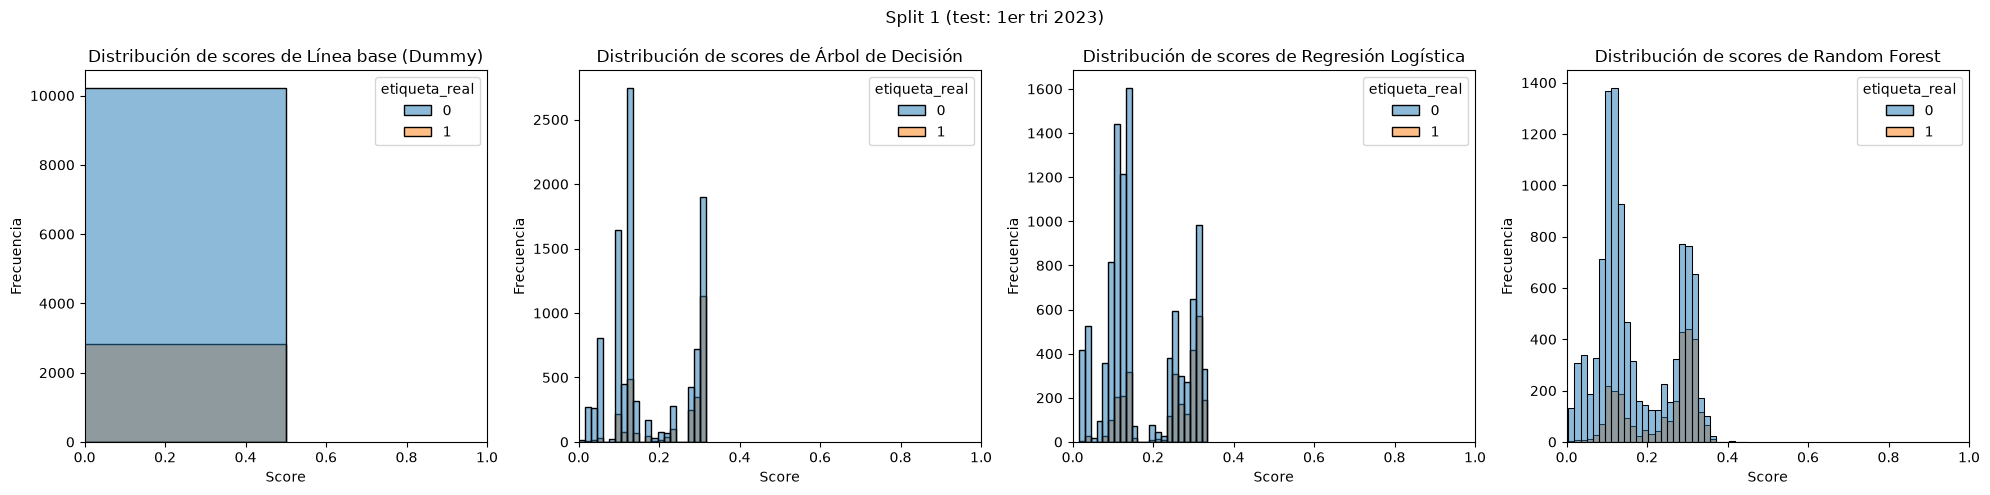

Split 2 (test: 2do tri 2023): train=69,668, prueba=13,344


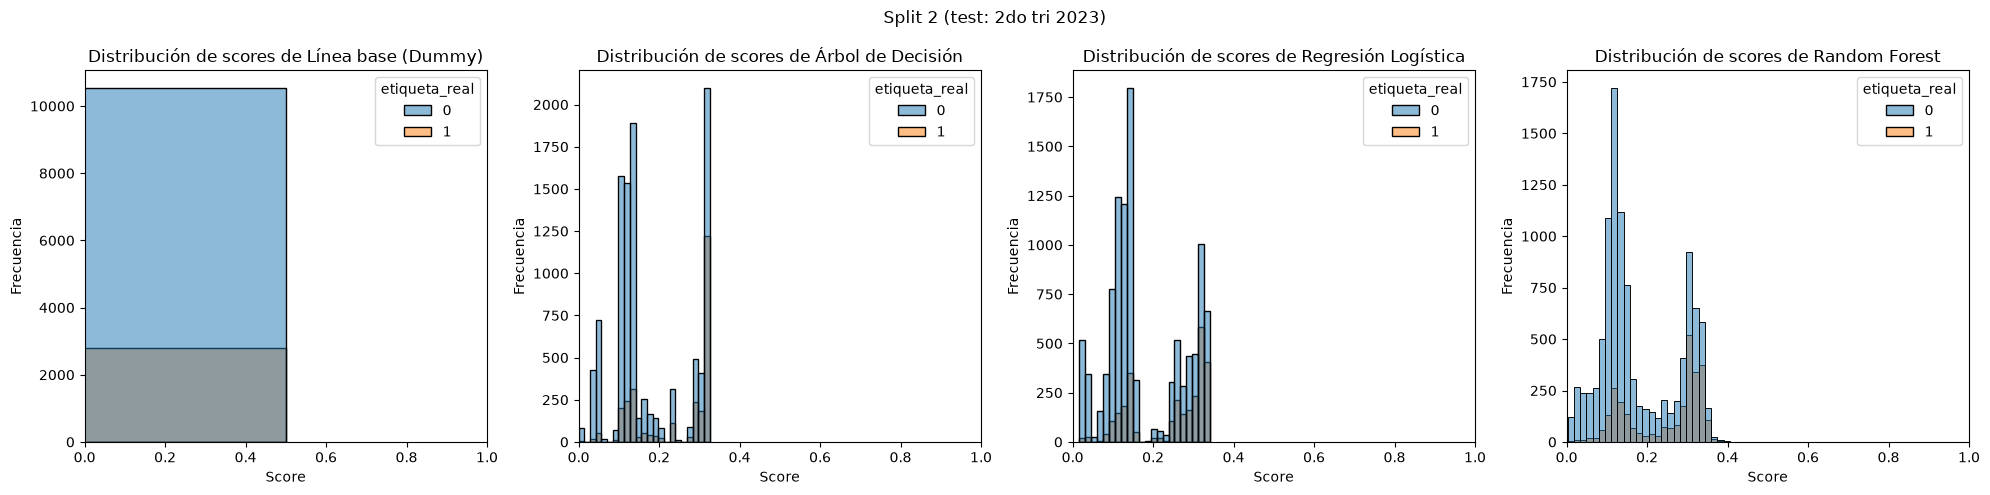

Split 3 (test: 3er tri 2023): train=83,012, prueba=14,278


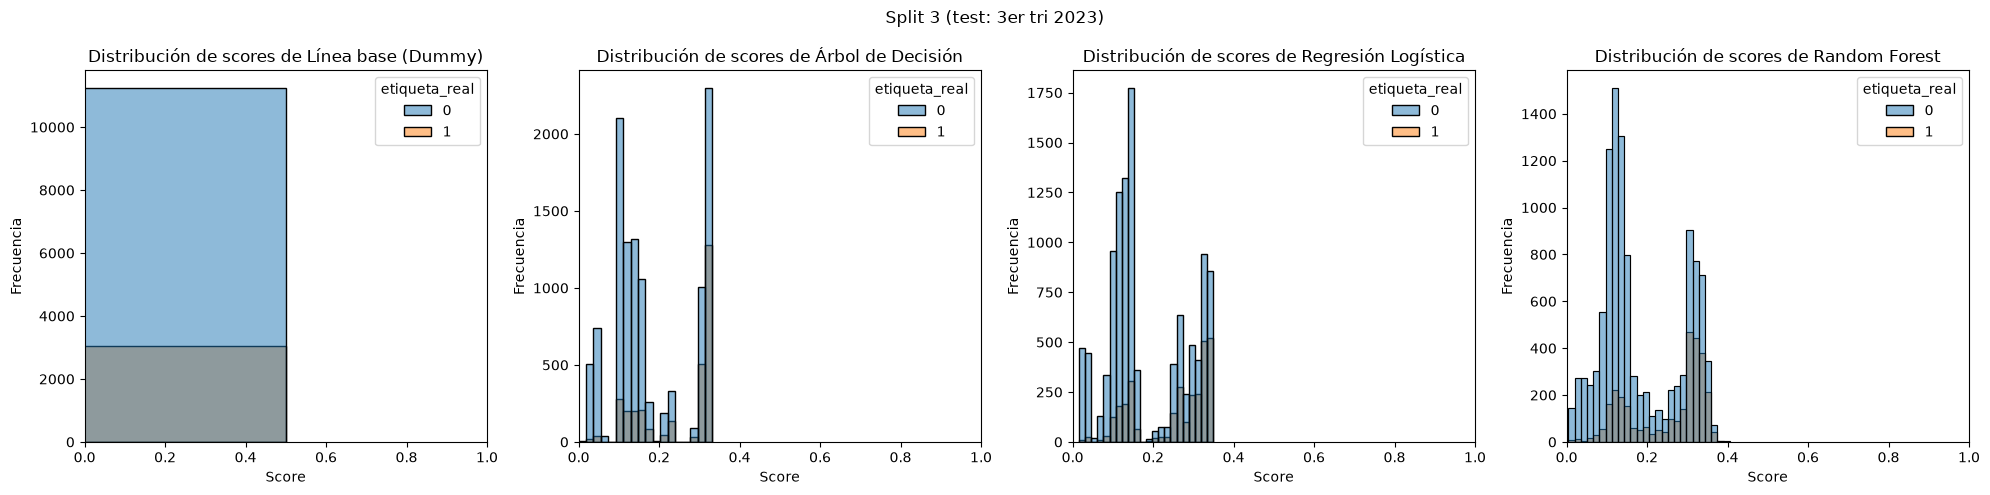

Split 4 (test: 4t0 tri 2023): train=97,290, prueba=15,372


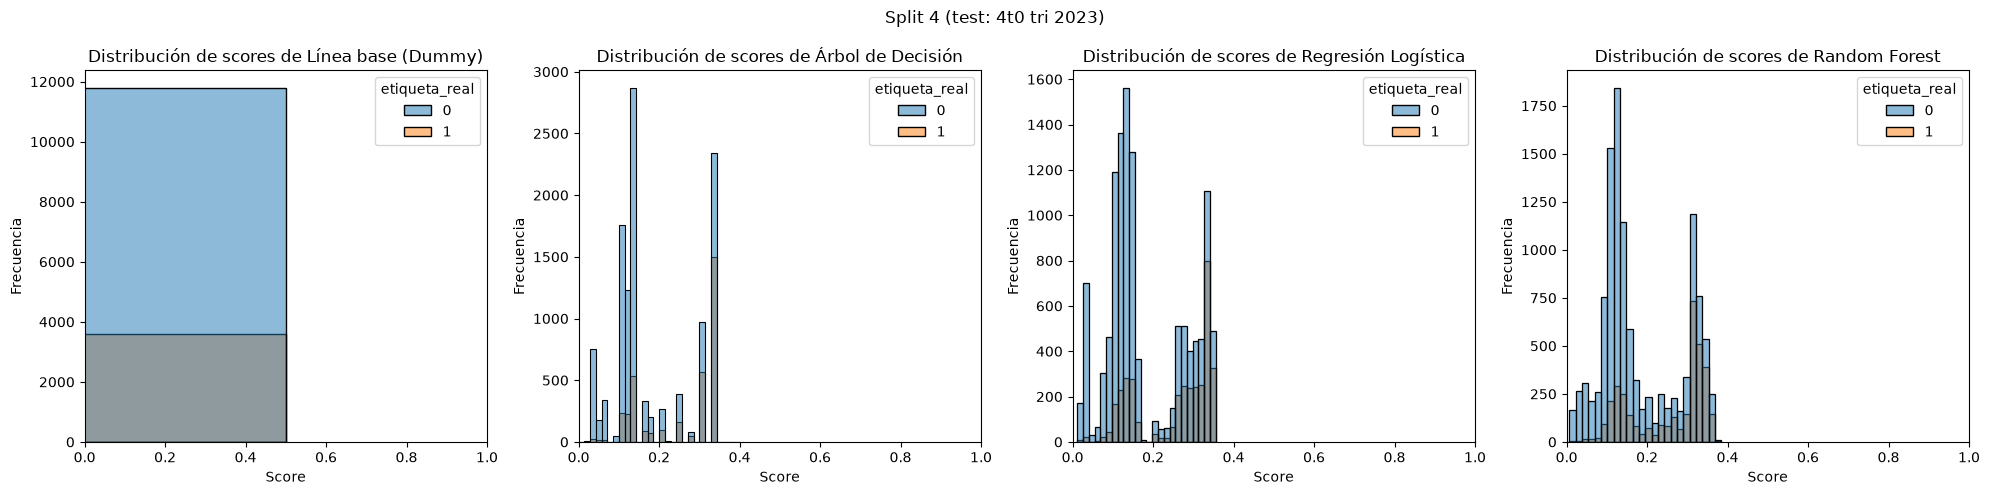

In [45]:
modelos_temporales = {
    'Línea base (Dummy)':  DummyClassifier(strategy='most_frequent', random_state=42),
    'Árbol de Decisión':   DecisionTreeClassifier(max_depth=5, random_state=42),
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),}

resultados_validacion = validar_temporal_scores(df_sorted,X,y,splits_temporales,modelos_temporales)

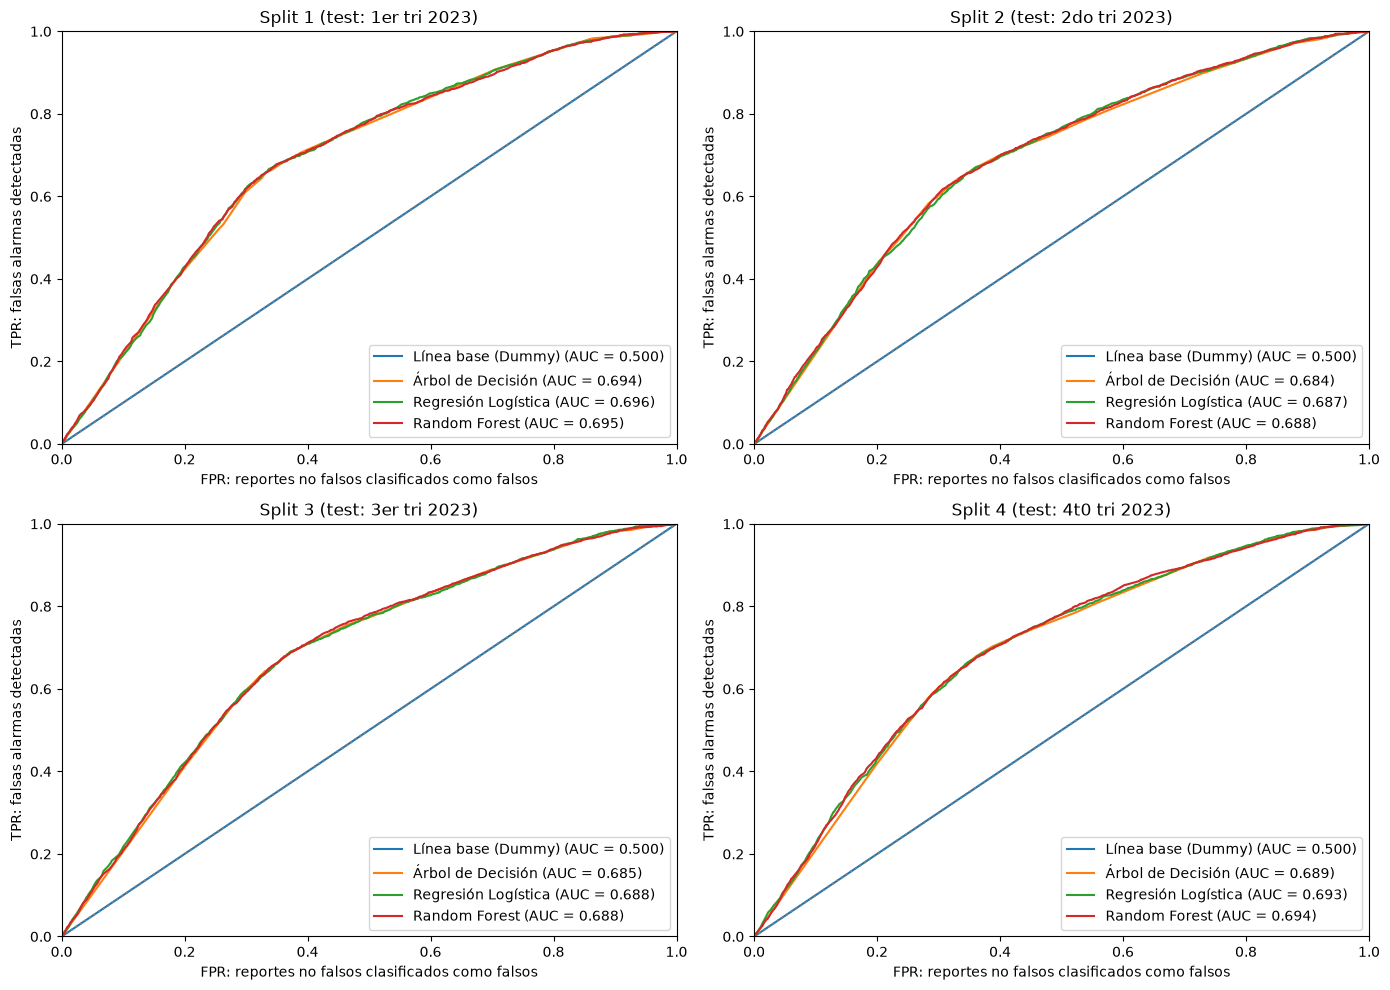

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, s in zip(axes, splits_temporales):

    resultados_split = resultados_validacion[s['nombre']]

    for nombre, df_res in resultados_split.items():
        if df_res['etiqueta_real'].nunique() < 2:
            continue

        fpr, tpr, _ = roc_curve(
            df_res['etiqueta_real'],
            df_res['score_falsa_alarma']
        )

        auc = roc_auc_score(
            df_res['etiqueta_real'],
            df_res['score_falsa_alarma']
        )

        ax.plot(fpr, tpr, label=f'{nombre} (AUC = {auc:.3f})')

    ax.plot([0, 1], [0, 1], linestyle=':', color='gray')
    ax.set_title(s['nombre'])
    ax.set_xlabel('FPR: reportes no falsos clasificados como falsos')
    ax.set_ylabel('TPR: falsas alarmas detectadas')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()

plt.tight_layout()
plt.show()

In [47]:
resumen_semanal = []

for nombre_split, resultados_split in resultados_validacion.items():

    for nombre_modelo, df_res in resultados_split.items():

        datos = df_res.copy()
        datos['fecha_hora_creacion'] = pd.to_datetime(
            datos['fecha_hora_creacion']
        )

        # Semana de lunes a domingo
        datos['semana'] = (
            datos['fecha_hora_creacion']
            .dt.to_period('W-SUN')
            .dt.start_time
        )

        for semana, datos_semana in datos.groupby('semana'):

            top_100 = datos_semana.nlargest(
                100, 'score_falsa_alarma'
            )

            total_reportes = len(datos_semana)
            falsas_alarmas_reales = (
                datos_semana['etiqueta_real'] == 1
            ).sum()

            falsas_alarmas_seleccionadas = (
                top_100['etiqueta_real'] == 1
            ).sum()

            resumen_semanal.append({
                'split': nombre_split,
                'modelo': nombre_modelo,
                'semana': semana,
                'total_reportes': total_reportes,
                'falsas_alarmas_reales': falsas_alarmas_reales,
                'tasa_base_semanal': (
                    falsas_alarmas_reales / total_reportes
                    if total_reportes > 0 else np.nan
                ),
                'reportes_seleccionados': len(top_100),
                'falsas_alarmas_seleccionadas':
                    falsas_alarmas_seleccionadas,
                'eficiencia@100': (
                    falsas_alarmas_seleccionadas / len(top_100)
                    if len(top_100) > 0 else np.nan
                ),
                'cobertura@100': (
                    falsas_alarmas_seleccionadas / falsas_alarmas_reales
                    if falsas_alarmas_reales > 0 else np.nan
                )
            })

df_resumen_semanal = pd.DataFrame(resumen_semanal)
df_resumen_semanal.head(1)


,split,modelo,semana,total_reportes,falsas_alarmas_reales,tasa_base_semanal,reportes_seleccionados,falsas_alarmas_seleccionadas,eficiencia@100,cobertura@100
0,Split 1 (test: 1er tri 2023),Línea base (Dummy),2022-12-26,109,25,0.229358,100,24,0.24,0.96


In [48]:
promedios_trimestrales = (
    df_resumen_semanal
    .groupby(['split', 'modelo'])
    .agg(
        tasa_base_promedio=('tasa_base_semanal', 'mean'),
        eficiencia_100_promedio=('eficiencia@100', 'mean'),
        cobertura_100_promedio=('cobertura@100', 'mean'),
        semanas=('semana', 'nunique'),
        semanas_con_cobertura=('cobertura@100', 'count')
    )
    .reset_index() )

promedios_trimestrales

,split,modelo,tasa_base_promedio,eficiencia_100_promedio,cobertura_100_promedio,semanas,semanas_con_cobertura
0,Split 1 (test: 1er tri 2023),Línea base (Dummy),0.219332,0.229286,0.167249,14,14
1,Split 1 (test: 1er tri 2023),Random Forest,0.219332,0.366429,0.231423,14,14
2,Split 1 (test: 1er tri 2023),Regresión Logística,0.219332,0.357143,0.223479,14,14
3,Split 1 (test: 1er tri 2023),Árbol de Decisión,0.219332,0.375714,0.234745,14,14
4,Split 2 (test: 2do tri 2023),Línea base (Dummy),0.210409,0.225714,0.137122,14,14
5,Split 2 (test: 2do tri 2023),Random Forest,0.210409,0.383571,0.215738,14,14
6,Split 2 (test: 2do tri 2023),Regresión Logística,0.210409,0.366429,0.205465,14,14
7,Split 2 (test: 2do tri 2023),Árbol de Decisión,0.210409,0.359286,0.205330,14,14
8,Split 3 (test: 3er tri 2023),Línea base (Dummy),0.210813,0.210000,0.109273,14,14
9,Split 3 (test: 3er tri 2023),Random Forest,0.210813,0.370000,0.192824,14,14


In [49]:
def eficiencia_cobertura_k(df_resultados, k):

    k_real = min(k, len(df_resultados))

    if k_real == 0:
        return np.nan, np.nan

    top_k = df_resultados.nlargest(
        k_real, 'score_falsa_alarma'
    )

    tp = (top_k['etiqueta_real'] == 1).sum()
    total_positivos = (df_resultados['etiqueta_real'] == 1).sum()

    eficiencia = tp / k_real
    cobertura = (
        tp / total_positivos
        if total_positivos > 0 else np.nan
    )

    return eficiencia, cobertura


k_valores = [25, 50, 75, 100, 150, 200]
resultados_k = []

for nombre_split, resultados_split in resultados_validacion.items():

    for nombre_modelo, df_res in resultados_split.items():

        datos = df_res.copy()
        datos['fecha_hora_creacion'] = pd.to_datetime(
            datos['fecha_hora_creacion']
        )
        datos['semana'] = (
            datos['fecha_hora_creacion']
            .dt.to_period('W-SUN')
            .dt.start_time
        )

        for semana, datos_semana in datos.groupby('semana'):

            for k in k_valores:

                eficiencia, cobertura = eficiencia_cobertura_k(
                    datos_semana, k
                )

                resultados_k.append({
                    'split': nombre_split,
                    'modelo': nombre_modelo,
                    'semana': semana,
                    'k': k,
                    'eficiencia@k': eficiencia,
                    'cobertura@k': cobertura
                })

df_resultados_k = pd.DataFrame(resultados_k)

In [50]:
curvas_trimestrales = (
    df_resultados_k
    .groupby(['split', 'modelo', 'k'])
    .agg(
        eficiencia_promedio=('eficiencia@k', 'mean'),
        cobertura_promedio=('cobertura@k', 'mean'),
        semanas_con_cobertura=('cobertura@k', 'count')
    )
    .reset_index())

curvas_trimestrales

,split,modelo,k,eficiencia_promedio,cobertura_promedio,semanas_con_cobertura
0,Split 1 (test: 1er tri 2023),Línea base (Dummy),25,0.222857,0.043484,14
1,Split 1 (test: 1er tri 2023),Línea base (Dummy),50,0.225714,0.082417,14
2,Split 1 (test: 1er tri 2023),Línea base (Dummy),75,0.225714,0.128958,14
3,Split 1 (test: 1er tri 2023),Línea base (Dummy),100,0.229286,0.167249,14
4,Split 1 (test: 1er tri 2023),Línea base (Dummy),150,0.222097,0.214414,14
...,...,...,...,...,...,...
91,Split 4 (test: 4t0 tri 2023),Árbol de Decisión,50,0.388571,0.113368,14
92,Split 4 (test: 4t0 tri 2023),Árbol de Decisión,75,0.391429,0.162817,14
93,Split 4 (test: 4t0 tri 2023),Árbol de Decisión,100,0.387857,0.205311,14
94,Split 4 (test: 4t0 tri 2023),Árbol de Decisión,150,0.380664,0.276568,14


NameError: name 'colores_modelos' is not defined

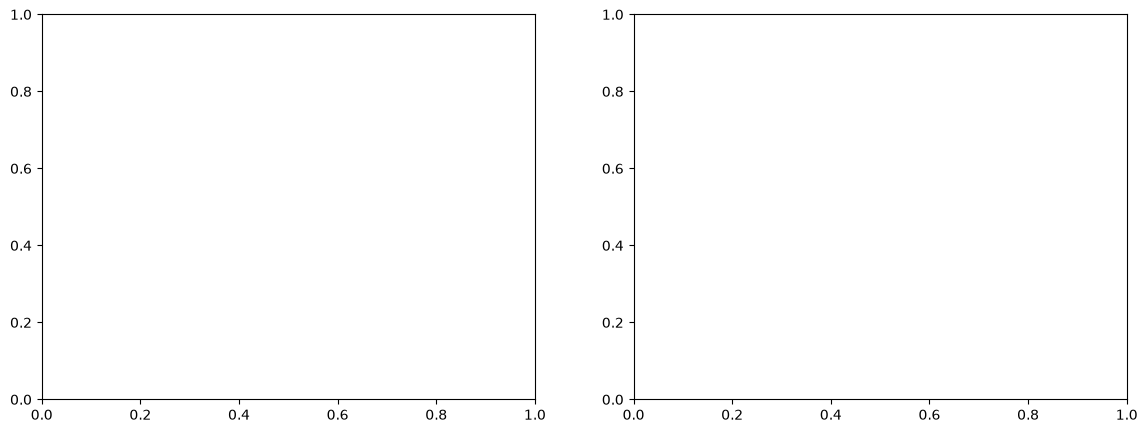

In [51]:
split_elegido = 'Split 4 (test: 4t0 tri 2023)'

datos_split = curvas_trimestrales[
    curvas_trimestrales['split'] == split_elegido
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nombre, color in colores_modelos.items():

    datos_modelo = datos_split[
        datos_split['modelo'] == nombre
    ].sort_values('k')

    if datos_modelo.empty:
        continue

    axes[0].plot(
        datos_modelo['k'],
        datos_modelo['eficiencia_promedio'],
        marker='o',
        label=nombre,
        color=color,
        linewidth=2
    )

    axes[1].plot(
        datos_modelo['k'],
        datos_modelo['cobertura_promedio'],
        marker='o',
        label=nombre,
        color=color,
        linewidth=2
    )

axes[0].set_title(f'Eficiencia@k — {split_elegido}')
axes[0].set_xlabel('Reportes seleccionados (k)')
axes[0].set_ylabel('Eficiencia promedio')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=9)

axes[1].set_title(f'Cobertura@k — {split_elegido}')
axes[1].set_xlabel('Reportes seleccionados (k)')
axes[1].set_ylabel('Cobertura promedio')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
### Implementación con ingeniera de variables
df_metricametricas_impl1 = df_metricas.copy()


### Implementación 2 

In [ ]:
modelos_temporales = {
  'Línea base (Dummy)':  DummyClassifier(strategy='most_frequent', random_state=42),
  'Árbol de Decisión':   DecisionTreeClassifier(max_depth=5, random_state=42),
  'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
  'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),}

variables_t = ['incidente_c4','tipo_incidente_c4','alcaldia_inicio','tipo_entrada','hora','dia']

columnas_categoricas = ['incidente_c4', 'tipo_incidente_c4', 'alcaldia_inicio', 'tipo_entrada']
columnas_numericas   = ['hora', 'dia']

X_cat = pd.get_dummies(df[columnas_categoricas], drop_first=True)
X_num = df[columnas_numericas]
X = pd.concat([X_cat, X_num], axis=1)

print(f'Dimensiones de X: {X.shape}  → {X.shape[0]:,} llamadas, {X.shape[1]} features')
print(f'Tasa de falsas alarmas y: {y.mean():.1%}')
X.head(1)

In [ ]:
resumen_semanal = []

for nombre_split, resultados_split in resultados_validacion.items():

    for nombre_modelo, df_res in resultados_split.items():

        datos = df_res.copy()
        datos['fecha_hora_creacion'] = pd.to_datetime(
            datos['fecha_hora_creacion']
        )

        # Semana de lunes a domingo
        datos['semana'] = (
            datos['fecha_hora_creacion']
            .dt.to_period('W-SUN')
            .dt.start_time
        )

        for semana, datos_semana in datos.groupby('semana'):

            top_100 = datos_semana.nlargest(
                100, 'score_falsa_alarma'
            )

            total_reportes = len(datos_semana)
            falsas_alarmas_reales = (
                datos_semana['etiqueta_real'] == 1
            ).sum()

            falsas_alarmas_seleccionadas = (
                top_100['etiqueta_real'] == 1
            ).sum()

            resumen_semanal.append({
                'split': nombre_split,
                'modelo': nombre_modelo,
                'semana': semana,
                'total_reportes': total_reportes,
                'falsas_alarmas_reales': falsas_alarmas_reales,
                'tasa_base_semanal': (
                    falsas_alarmas_reales / total_reportes
                    if total_reportes > 0 else np.nan
                ),
                'reportes_seleccionados': len(top_100),
                'falsas_alarmas_seleccionadas':
                    falsas_alarmas_seleccionadas,
                'eficiencia@100': (
                    falsas_alarmas_seleccionadas / len(top_100)
                    if len(top_100) > 0 else np.nan
                ),
                'cobertura@100': (
                    falsas_alarmas_seleccionadas / falsas_alarmas_reales
                    if falsas_alarmas_reales > 0 else np.nan
                )
            })

df_resumen_semanal = pd.DataFrame(resumen_semanal)
df_resumen_semanal.head(1)

In [ ]:
### QUIEN SABE PORQUE NO SE SUIO 

In [ ]:
### SsSSs